# matplotlib の描画関数

この章では、よく使うグラフの描き方を紹介します。どの関数にも属性を決めるキーワード引数がたくさんありますが、全部は紹介しません。細かい設定が必要になったら、関数の説明か、公式のデモを見てください。

## この章で学ぶこと

* 対数座標と極座標
* 棒グラフと散布図
* 画像と等高線
* メッシュ(`pcolormesh`、三角形メッシュ)
* ベクトル場(`quiver`)
* 3 次元の曲面

In [1]:
import numpy as np
import helper.matplotlib
from matplotlib import pyplot as plt
from matplotlib import cm

## 対数座標のグラフ

`plot()` の x 軸と y 軸は、どちらも普通の数直線でした。対数座標で描く関数は 3 つあります。

* `semilogx()`：x 軸が対数
* `semilogy()`：y 軸が対数
* `loglog()`：両方とも対数

次のプログラムは、ローパスフィルタの周波数応答を 4 つの座標で描きます。左上が `plot()`、右上が `semilogx()`、左下が `semilogy()`、右下が `loglog()` です。両対数の図をボード線図と呼びます。

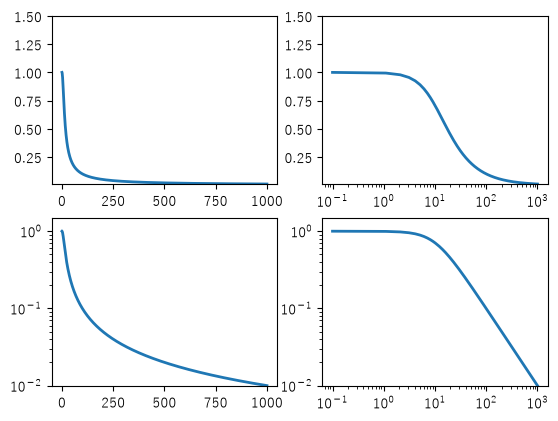

In [2]:
w = np.linspace(0.1, 1000, 1000)
p = np.abs(1 / (1 + 0.1j * w))  # ローパスフィルタの周波数応答を計算

fig, axes = plt.subplots(2, 2)

functions = ("plot", "semilogx", "semilogy", "loglog")

for ax, fname in zip(axes.ravel(), functions):
    func = getattr(ax, fname)
    func(w, p, linewidth=2)
    ax.set_ylim(0.01, 1.5)

## 極座標のグラフ

極座標では、点を中心からの角度と距離で表します。次のプログラムは極座標のグラフを描きます。

(<a list of 4 Line2D ticklines objects>,
 [Text(0.0, 0, '0°'), Text(0.7853981633974483, 0, '45°')])

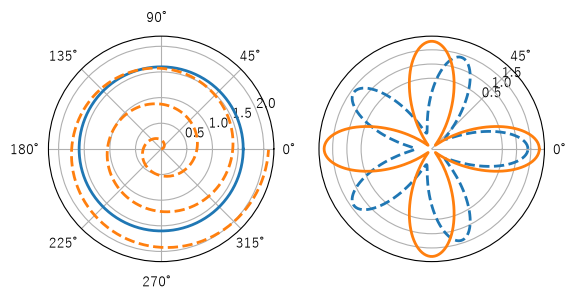

In [3]:
theta = np.arange(0, 2 * np.pi, 0.02)

plt.subplot(121, polar=True)  #❶
plt.plot(theta, 1.6 * np.ones_like(theta), linewidth=2)  #❷
plt.plot(3 * theta, theta / 3, "--", linewidth=2)

plt.subplot(122, polar=True)
plt.plot(theta, 1.4 * np.cos(5 * theta), "--", linewidth=2)
plt.plot(theta, 1.8 * np.cos(4 * theta), linewidth=2)
plt.rgrids(np.arange(0.5, 2, 0.5), angle=45)  #❸
plt.thetagrids([0, 45])  #❹;

❶ `subplot()` に `polar=True` を渡すと、極座標のサブプロットになります。❷ そのあと `plot()` で曲線を描きます。`polar()` で直接作ることもできます。

❸ `rgrids()` は同心円の半径と、その文字を置く角度を決めます。右の図では半径 0.5、1.0、1.5 の円が 3 つあり、文字は 45 度の線に沿っています。❹ `thetagrids()` は放射状の線の角度を決めます。右の図では 0 度と 45 度の 2 本です。

## 棒グラフ

棒グラフは、棒の長さで値を表し、いくつかの群を比べるのに使います。次のプログラムは、中国の年齢別の人口(Wikipedia のデータで、正確さは保証しません)を読み、男女を並べて比べます。

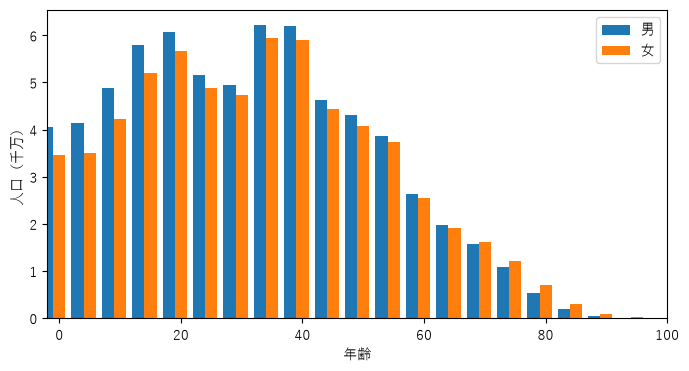

In [4]:
data = np.loadtxt("data/china_population.txt")
width = (data[1, 0] - data[0, 0]) * 0.4  #❶
plt.figure(figsize=(8, 4))
plt.bar(data[:, 0] - width, data[:, 1] / 1e7, width, label="男")  #❷
plt.bar(data[:, 0], data[:, 2] / 1e7, width, label="女")  #❸
plt.xlim(-width, 100)
plt.xlabel("年齢")
plt.ylabel("人口（千万）")
plt.legend();

読み込んだデータの 1 列目が年齢で、横軸になります。❶ まず棒の幅を決めます。1 つの年齢に 2 本の棒を並べるので、幅は年齢の間隔より小さくします。ここでは間隔の 0.4 倍です。

❷ `bar()` で男性の棒を描きます。第 1 引数が棒の左端の x 座標です。男女の棒が年齢の目盛りをはさむように、左端を「年齢 - 幅」にします。第 2 引数が高さ、第 3 引数が幅です。幅に並びを渡せば、棒ごとに変えられます。

❸ 女性の棒は、左端を年齢にして描きます。

## 散布図

`plot()` の書式に点だけを指定すると、散布図になります。

```python
plt.plot(np.random.random(100), np.random.random(100), "o")
```

ただし、この方法では点ごとに色や大きさを変えられません。`scatter()` なら変えられます。

次のプログラムは `scatter()` の使い方です。

C:\Users\ruoyu\AppData\Local\Temp\ipykernel_11332\331269464.py:4: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(x, y, s=x * 1000, c=y, marker=(5, 1), alpha=0.8, lw=2, facecolors="none")


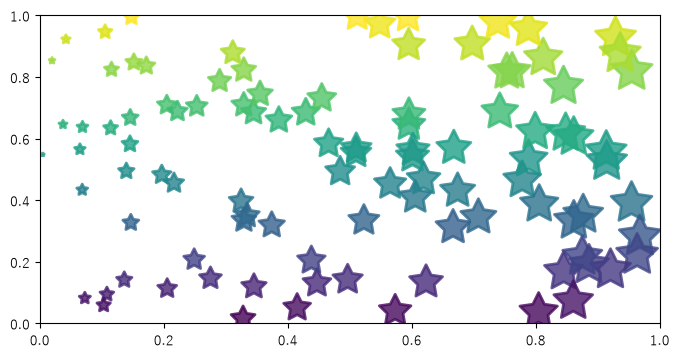

In [5]:
plt.figure(figsize=(8, 4))
x = np.random.random(100)
y = np.random.random(100)
plt.scatter(x, y, s=x * 1000, c=y, marker=(5, 1), alpha=0.8, lw=2, facecolors="none")
plt.xlim(0, 1)
plt.ylim(0, 1);

`scatter()` の最初の 2 つの引数が、各点の x と y です。`s` は点の面積、`c` は色で、どちらも 1 つの値か配列を渡せます。`c` に並びを渡すと、カラーマップで色が決まります。既定では小さい値が青、大きい値が赤です。`c` が形 `(N, 3)` か `(N, 4)` の 2 次元配列なら、RGB の色をそのまま指定できます。

`marker` は点の形で、文字列か 2 つの数のタプルで決めます。1 つ目が多角形の辺の数、2 つ目が 0〜3 の種類で、0 が多角形、1 が星、2 が放射状、3 が円です。`alpha` は透明度、`lw` は線の太さ、`facecolors="none"` で塗りをなしにします。

## 画像

`imread()` と `imshow()` で、画像を読み込んで表示できます。`imread()` は画像を NumPy 配列にします。第 1 引数がファイル名かファイルのオブジェクトで、`format` を省くと拡張子で形式を決めます。白黒なら `(M, N)`、カラーなら `(M, N, C)` の配列で、`C` は 3 か 4 です。

次のプログラムは `vinci_target.png` を読みます。PNG を読むと、値が 0.0〜1.0 に正規化された `float32` の配列になるので、`(img * 255).astype(np.uint8)` で 1 バイトに戻します。

:::{note}
`imread()` の戻りの型は、形式で変わります。PNG は 0.0〜1.0 の `float32` になります。JPEG は 8 ビットの `uint8` のままです。JPEG では正規化しないためです。
:::

In [6]:
img = plt.imread("data/vinci_target.png")
img = (img * 255).astype(np.uint8)
print(img.shape, img.dtype)

(505, 375, 3) uint8


`imshow()` で画像を表示します。

❶ 3 次元の配列を渡すと、各チャンネルの値で色が決まります。❷ `imshow()` は既定で y 軸を上から下に取ります。`origin="lower"` にすると原点が左下になりますが、画像は上下が逆になります。❸ 3 次元の配列が浮動小数点数のときは、値の範囲を 0.0〜1.0 にします。超えると色がおかしくなります。❹ 0〜1 に収めた配列なら、元の画像と同じです。❺ `clip()` で範囲外を抑えると、全体が明るくなります。

❻ 2 次元の配列を渡すと、カラーマップで色が決まります。ここでは赤のチャンネルを出します。既定では小さい値が青、大きい値が赤になるので、見た目は不自然です。`colorbar()` で対応を出せます。❼ `cmap` でカラーマップを変えられます。

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..242.0].


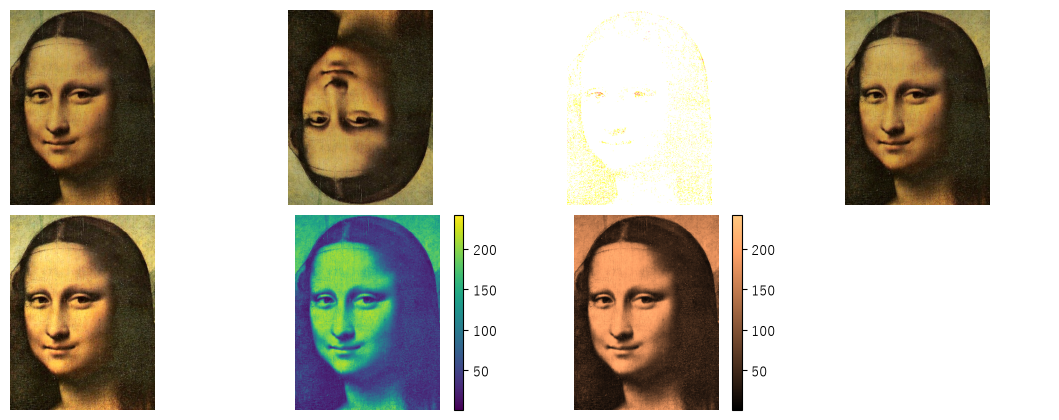

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(11, 4))
fig.subplots_adjust(0, 0, 1, 1, 0.05, 0.05)

axes = axes.ravel()

axes[0].imshow(img)  #❶
axes[1].imshow(img, origin="lower")  #❷
axes[2].imshow(img * 1.0)  #❸
axes[3].imshow(img / 255.0)  #❹
axes[4].imshow(np.clip(img / 200.0, 0, 1))  #❺

axe_img = axes[5].imshow(img[:, :, 0])  #❻
plt.colorbar(axe_img, ax=axes[5])

axe_img = axes[6].imshow(img[:, :, 0], cmap="copper")  #❼
plt.colorbar(axe_img, ax=axes[6])

for ax in axes:
    ax.set_axis_off()

カラーマップは `ColorMap` オブジェクトで、matplotlib にたくさん用意されています。名前は次のコードで分かります。

In [8]:
plt.colormaps()[:5]

['magma', 'inferno', 'plasma', 'viridis', 'cividis']

`imshow()` は、2 次元のデータなら何でも表示できます。次のプログラムは、2 変数の関数 $f(x,y) = x e^{-x^2-y^2}$ を画像で表します。

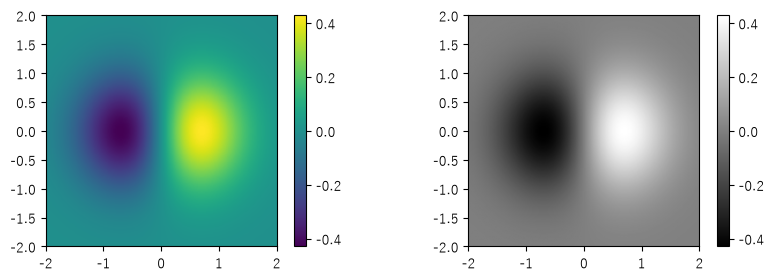

In [9]:
y, x = np.ogrid[-2:2:200j, -2:2:200j]
z = x * np.exp(-(x**2) - y**2)  #❶

extent = [np.min(x), np.max(x), np.min(y), np.max(y)]  #❷

plt.figure(figsize=(10, 3))
plt.subplot(121)
plt.imshow(z, extent=extent, origin="lower")  #❷
plt.colorbar()
plt.subplot(122)
plt.imshow(z, extent=extent, cmap=cm.gray, origin="lower")
plt.colorbar();

❶ ブロードキャストで、関数の値を 2 次元配列 `z` にします。第 0 軸が y、第 1 軸が x です。❷ x と y の範囲を `extent` に入れます。❸ `extent` を渡すと、軸の目盛りがその範囲になります。

## 等高線図

2 変数の関数は、等高線でも表せます。等高線は、値が同じ点を結んだ線です。線が密なところは、値が急に変わる場所です。matplotlib では `contour()` と `contourf()` を使います。`contourf()` は塗りつぶします。

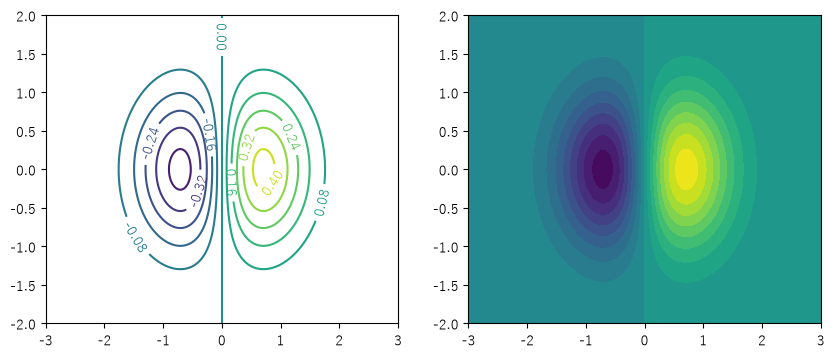

In [10]:
y, x = np.ogrid[-2:2:200j, -3:3:300j]  #❶
z = x * np.exp(-(x**2) - y**2)

extent = [np.min(x), np.max(x), np.min(y), np.max(y)]

plt.figure(figsize=(10, 4))
plt.subplot(121)
cs = plt.contour(z, 10, extent=extent)  #❷
plt.clabel(cs)  #❸
plt.subplot(122)
plt.contourf(x.reshape(-1), y.reshape(-1), z, 20)  #❹;

❶ x と y で範囲と分割数を変えて、区別しやすくします。`z` の形は `(200, 300)` で、第 0 軸が y、第 1 軸が x です。

❷ `contour()` で等高線を描きます。第 2 引数の 10 は区間の数で、線は 9 本になります。`extent` で軸の範囲を指定できます。❸ `contour()` が返す `QuadContourSet` を `clabel()` に渡すと、線に値が付きます。

❹ `contourf()` は塗りつぶします。ここでは x と y を渡す書き方にしています。第 1、第 2 引数は、`z` を計算したときの x と y の点で、1 次元配列か `z` と同じ形の配列です。

:::{tip}
ばらばらの点のデータで等高線を描きたいときは、`scipy.interpolate` の補間で格子のデータにしてから描きます。
:::

等高線で、陰関数の曲線も描けます。陰関数とは、$f(x,y)=0$ が $x$ から $y$ を決める関係のことです。たとえば $x^2+y^2-1=0$ は単位円です。

ふつうの関数のように x の並びを作って y を計算する、という方法は使えません。そこで等高線を使います。陰関数の曲線は、値が 0 の等高線です。次のプログラムは、次の関数を $f(x,y)=0$ と $f(x,y)-0.1=0$ で描きます。

$$f(x,y)=(x^2+y^2)^4 - (x^2-y^2)^2$$

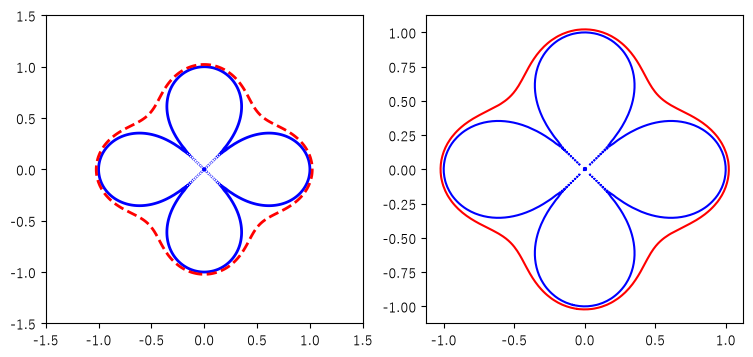

In [11]:
y, x = np.ogrid[-1.5:1.5:200j, -1.5:1.5:200j]
f = (x**2 + y**2) ** 4 - (x**2 - y**2) ** 2

plt.figure(figsize=(9, 4))
plt.subplot(121)
extent = [np.min(x), np.max(x), np.min(y), np.max(y)]
cs = plt.contour(
    f,
    extent=extent,
    levels=[0.0, 0.1],  #❶
    colors=["b", "r"],
    linestyles=["solid", "dashed"],
    linewidths=[2, 2],
)

plt.subplot(122)
for i, p in enumerate(cs.get_paths()):  #❷
    color = cs.get_edgecolors()[i]
    for poly in p.to_polygons():
        plt.plot(poly[:, 0], poly[:, 1], color=color)

❶ `contour()` の `levels` で、等高線の値を指定します。ここでは `[0, 0.1]` なので 2 本です。`colors`、`linestyles`、`linewidths` で、それぞれの線の色、種類、太さを決めます。

左の図で、$f(x,y)=0$ の青い実線が途切れていることに気づきます。原点の近くで等高線が限りなく近づくので、値をどう細かく刻んでも分けられない部分が残るためです。一方、$f(x,y)-0.1=0$ の赤い破線は閉じています。

❷ `cs` から各等高線のパスを取り、`plot()` で描き直します。

`contour()` が返す `QuadContourSet` の属性から、等高線の情報を取れます。

In [12]:
print(cs)

等高線ごとに、色、線種、太さなどの属性があります。次のコードで色と太さを取ります。

In [13]:
print(cs.get_edgecolors())
print(cs.get_linewidths())

[[0. 0. 1. 1.]
 [1. 0. 0. 1.]]
[2 2]


`get_paths()` は、等高線を作るパスをすべて返します。1 つのパスがいくつかの部分に分かれることもあります。`to_polygons()` でパスを多角形のリストにできます。この例の青い実線は、42 個のパスでできています。

In [14]:
print(len(cs.get_paths()))
path0 = cs.get_paths()[0]
len(path0.to_polygons())

2


42

パスは `Path` オブジェクトで、`vertices` にすべての点の座標が入っています。

In [15]:
path1 = cs.get_paths()[1]
path1.vertices

array([[-0.05276382, -1.01841473],
       [-0.05830807, -1.01758794],
       [-0.0678392 , -1.01594938],
       ...,
       [-0.02261307, -1.02126475],
       [-0.03768844, -1.02011677],
       [-0.05276382, -1.01841473]], shape=(545, 2))

## 四角形メッシュ

`pcolormesh(X, Y, C)` は、`X`、`Y`、`C` の 3 つの配列で決まる四角形のメッシュを描きます。`X` と `Y` は同じ形の 2 次元配列で、`C` はそれと同じか、1 行 1 列小さい形です。

四角形の 4 つの頂点の x 座標は、`X` の隣り合う 4 つの要素、y 座標は `Y` の同じ 4 つで決まります。色は `C` の値とカラーマップで決まります。

`shading` には 3 つの書き方があります。

* `'flat'`：`C` が `X` より 1 行 1 列小さいときに自動で選ばれる。
* `'nearest'`：`X` と `Y` を 1 行 1 列大きくしてから、`flat` で描く。
* `'gouraud'`：3 つとも同じ大きさで、四角形の中の色は 4 つの頂点の色を混ぜて決める。

次の例では、`X` と `Y` の形が `(2, 3)` で、隣り合う 4 つの要素の組が 2 つあり、2 つの四角形の頂点になります。

```
 最初の四角形の頂点      2番目の四角形の頂点
=================      ================
(0, 0), (1, 0.2)       (1, 0.2), (2, 0)
(0, 1), (1, 0.8)       (1, 0.8), (2, 1)
```

`C` の形は `(1, 2)` で、各四角形の色を決めます。このとき `flat` になります。`X` と `Y` を平らにして `plot()` で頂点を描き、`pcolormesh()` で四角形を描きます。左の四角形の値は 0.5、右は 0.8 なので、片方は紫、片方は黄色になります。

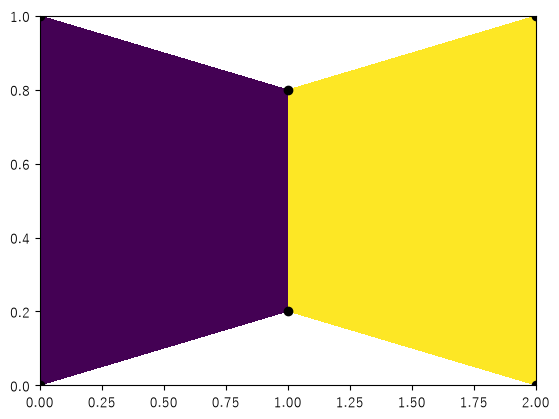

In [16]:
X = np.array([[0, 1, 2], [0, 1, 2]])
Y = np.array([[0, 0.2, 0], [1, 0.8, 1]])
C = np.array([[0.5, 0.8]])

plt.plot(X.ravel(), Y.ravel(), "ko")
plt.pcolormesh(X, Y, C)
plt.margins(0.1);

次の例は、複素平面の座標変換を `pcolormesh()` で描きます。`test_pcolormesh_shading()` で 3 つの書き方を並べます。

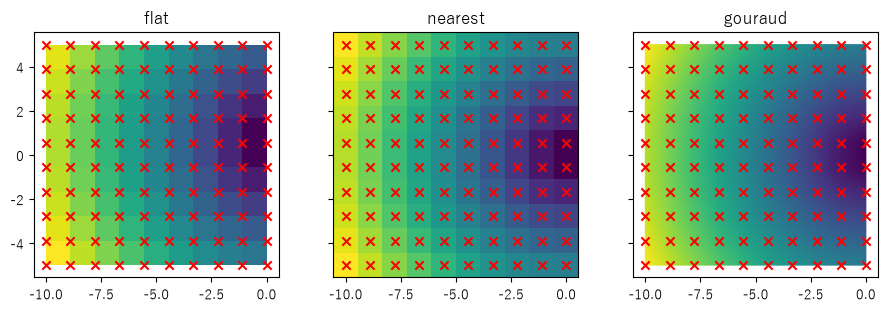

In [17]:
def test_pcolormesh_shading(X, Y, C):
    fig, axes = plt.subplots(
        1, 3, figsize=(9, 3), sharex=True, sharey=True, layout="constrained"
    )
    for ax in axes:
        ax.set_aspect("equal")
    axes[0].set_title("flat")
    axes[0].pcolormesh(X, Y, C[:-1, :-1], shading="flat")
    axes[0].scatter(X, Y, marker="x", color="red")

    axes[1].set_title("nearest")
    axes[1].pcolormesh(X, Y, C, shading="nearest")
    axes[1].scatter(X, Y, marker="x", color="red")

    axes[2].set_title("gouraud")
    axes[2].pcolormesh(X, Y, C, shading="gouraud")
    axes[2].scatter(X, Y, marker="x", color="red")
    return fig


n = 10
x, y = np.mgrid[-10 : 0 : n * 1j, -5 : 5 : n * 1j]
s = x + 1j * y
test_pcolormesh_shading(s.real, s.imag, np.abs(s));

`flat` では、`X` と `Y` が四角形の頂点で、色は `C` で決まります。`nearest` では、`X` と `Y` が四角形の中心です。`gouraud` では、`X` と `Y` が頂点で、色がなめらかに変わります。

次の図は、$z = \frac{2 + s}{2 - s}$ で変換したメッシュです。このとき `X` と `Y` は長方形の格子ではないので、`nearest` では中心を計算できず、警告が出ます。

C:\Users\ruoyu\AppData\Local\Temp\ipykernel_11332\1452107936.py:12: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  axes[1].pcolormesh(X, Y, C, shading="nearest")


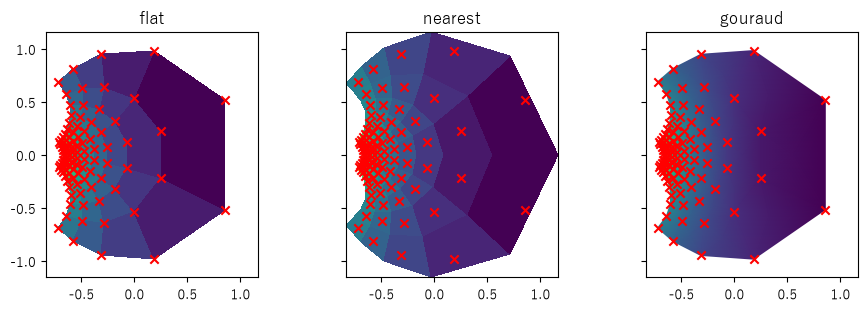

In [18]:
z = (2 + s) / (2 - s)
test_pcolormesh_shading(z.real, z.imag, np.abs(s));

極座標でも `pcolormesh()` が使えます。次の例は `mgrid()` で極座標の格子を作り、`projection="polar"` のサブプロットに描きます。

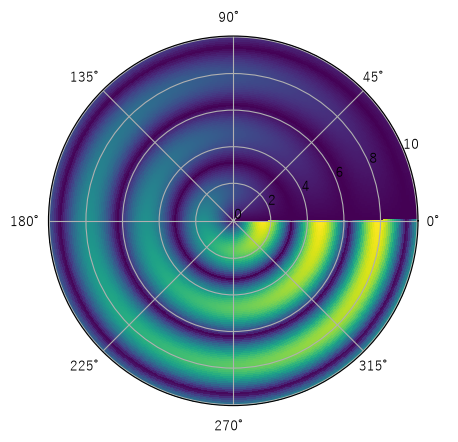

In [19]:
def func(theta, r):
    y = theta * np.sin(r)
    return np.sqrt(y * y)


T, R = np.mgrid[0 : 2 * np.pi : 360j, 0:10:100j]
Z = func(T, R)

ax = plt.subplot(111, projection="polar", aspect=1.0)
ax.pcolormesh(T, R, Z, rasterized=True);

## 三角形メッシュ

ものづくりの解析では、対象を三角形に分けて、有限要素法で計算します。matplotlib には、その表示のための関数があります。

* `triplot()`：三角形の辺を描く
* `tripcolor()`：塗りつぶした三角形を描く
* `tricontour()`、`tricontourf()`：三角形の上の等高線を描く

`diffusion.txt` は、FiPy で 2 次元の定常熱伝導を有限要素法で解いた結果です。ファイルは 3 つの部分に分かれます。

* `#points`：点の座標。形は `(N_points, 2)`。
* `#triangles`：各三角形の 3 つの頂点の番号。形は `(N_triangles, 3)`。
* `#values`：各三角形の温度。形は `(N_triangles, 1)`。

次のプログラムは、このデータを `data` 辞書に読みます。

In [20]:
with open("data/diffusion.txt") as f:
    data = {"points": [], "triangles": [], "values": []}
    values = None
    for line in f:
        line = line.strip()
        if not line:
            continue
        if line.startswith("#"):
            values = data[line[1:]]
            continue
        values.append([float(s) for s in line.split()])

data = {key: np.array(data[key]) for key in data}

`trip*()` で、領域の温度を表示します。

❶ `tripcolor()` の引数は、点の x、点の y、三角形の頂点番号、値の配列です。値は各頂点に対応するか、各三角形に対応します。ここでは `values` の長さが三角形の数と同じなので、三角形ごとの値です。頂点の数と同じなら、三角形の値は 3 つの頂点の平均になります。

❷ `triplot()` で三角形の辺を描きます。❸ `tricontour()` で等高線を描きます。こちらは値が頂点に対応している必要があるので、まず各三角形の重心 `Xc`、`Yc` を計算し、値を重心の値として渡します。頂点番号を渡さなければ、matplotlib が三角形分割をします。

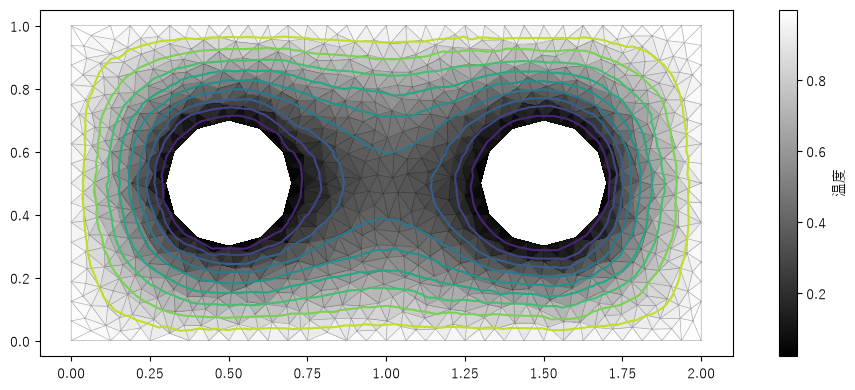

In [21]:
X, Y = data["points"].T
triangles = data["triangles"].astype(int)
values = data["values"].squeeze()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.set_aspect("equal")

mapper = ax.tripcolor(X, Y, triangles, values, cmap="gray")  #❶
plt.colorbar(mapper, label="温度")

plt.triplot(X, Y, triangles, lw=0.5, alpha=0.3, color="k")  #❷

Xc = X[triangles].mean(axis=1)
Yc = Y[triangles].mean(axis=1)
plt.tricontour(Xc, Yc, values, 10)  #❸;

## 矢印図

`quiver()` は、たくさんの矢印でベクトル場を表します。次のプログラムは、$f(x,y) = x e^{-x^2-y^2}$ の勾配を描きます。`vec_field()` は、偏微分を数値で近似します。

`quiver()` の最初の 5 つの引数は、矢印の始点の `X`、`Y`、方向と大きさの `U`、`V`、そして値の `C` です。

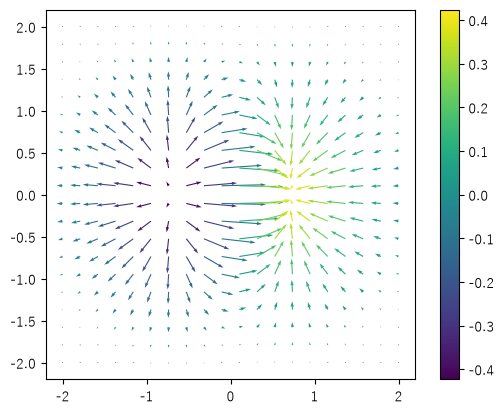

In [22]:
def f(x, y):
    return x * np.exp(-(x**2) - y**2)


def vec_field(f, x, y, dx=1e-6, dy=1e-6):
    x2 = x + dx
    y2 = y + dy
    v = f(x, y)
    vx = (f(x2, y) - v) / dx
    vy = (f(x, y2) - v) / dy
    return vx, vy


X, Y = np.mgrid[-2:2:20j, -2:2:20j]
C = f(X, Y)
U, V = vec_field(f, X, Y)
plt.quiver(X, Y, U, V, C)
plt.colorbar()
plt.gca().set_aspect("equal")

矢印の大きさと向きは、たくさんの引数で決めます。

* 長さは `scale` と `scale_units` で決まる。`scale_units` は `'width'`、`'height'`、`'dots'`、`'inches'`、`'x'`、`'y'`、`'xy'` から選ぶ。長さは「ベクトルの長さ × 単位 ÷ scale」になる。たとえば `scale=2`、`scale_units='x'`、ベクトルの長さ 3 なら、矢印は x 軸の 1.5 単位になる。

* `width`、`headwidth`、`headlength`、`headaxislength` が、軸の太さと矢じりの大きさを決める。`units` がその単位になる。

* `pivot` が回転の中心で、`'tail'`、`'middle'`、`'tip'` から選ぶ。

* `angles` が向きの決め方で、`'uv'` と `'xy'` がある。`'uv'` は `U` と `V` だけで決めるので、同じ値なら 45 度になる。`'xy'` は軸の縮尺も考える。

![quiver の各パラメータの意味](images/quiver_arrow.png)

2 つの例で使い方を見ます。まず、パラメータで表した曲線の上に、等間隔で 40 本の矢印を描きます。向きは曲線の接線、色はパラメータの値です。

長さの単位は `scale_units` と `units` で決まり、ここでは両方 `'dots'`(ピクセル)です。`dx` と `dy` の長さを 1 にして、`scale=1.0/arrow_size` とすると、矢印の長さが `arrow_size` ピクセルになります。軸の幅は `width` で 1 ピクセル、`headwidth` などは軸の幅に対する比です。この例では矢じりが長さ全体を占めるので、軸が見えません。

x 軸と y 軸の縮尺が違うので、`angles="xy"` にして、矢印が接線に沿うようにします。

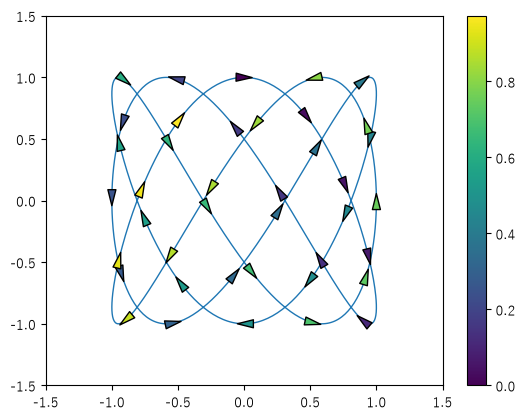

In [23]:
n = 40
arrow_size = 16
t = np.linspace(0, 1, 1000)
x = np.sin(3 * 2 * np.pi * t)
y = np.cos(5 * 2 * np.pi * t)
(line,) = plt.plot(x, y, lw=1)

lengths = np.cumsum(np.hypot(np.diff(x), np.diff(y)))
length = lengths[-1]
arrow_locations = np.linspace(0, length, n, endpoint=False)
index = np.searchsorted(lengths, arrow_locations)
dx = x[index + 1] - x[index]
dy = y[index + 1] - y[index]
ds = np.hypot(dx, dy)
dx /= ds
dy /= ds
plt.quiver(
    x[index],
    y[index],
    dx,
    dy,
    t[index],
    units="dots",
    scale_units="dots",
    angles="xy",
    scale=1.0 / arrow_size,
    pivot="middle",
    edgecolors="black",
    linewidths=1,
    width=1,
    headwidth=arrow_size * 0.5,
    headlength=arrow_size,
    headaxislength=arrow_size,
    zorder=100,
)
plt.colorbar()
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5]);

始点と終点を渡して、矢印を描くこともできます。次の例は、ニューラルネットワークの構造を描きます。`scale_units` と `angles` を `"xy"`、`scale` を 1 にすると、矢印の長さがデータの座標での長さになります。

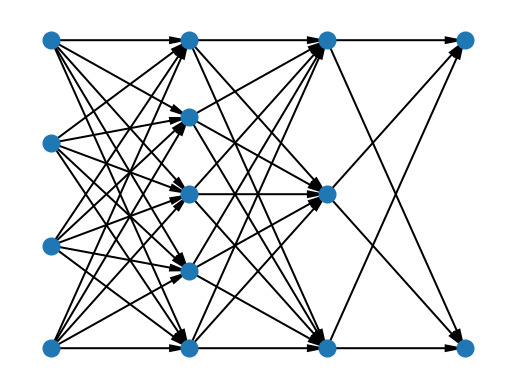

In [24]:
levels = [4, 5, 3, 2]
x = np.linspace(0, 1, len(levels))

for i in range(len(levels) - 1):
    j = i + 1
    n1, n2 = levels[i], levels[j]
    y1, y2 = np.mgrid[0 : 1 : n1 * 1j, 0 : 1 : n2 * 1j]
    x1 = np.full_like(y1, x[i])
    x2 = np.full_like(y2, x[j])
    plt.quiver(
        x1,
        y1,
        x2 - x1,
        y2 - y1,
        angles="xy",
        units="dots",
        scale_units="xy",
        scale=1,
        width=2,
        headlength=10,
        headaxislength=10,
        headwidth=4,
    )

yp = np.concatenate([np.linspace(0, 1, n) for n in levels])
xp = np.repeat(x, levels)
plt.plot(xp, yp, "o", ms=12)
plt.gca().axis("off")
plt.margins(0.1, 0.1);

## 3 次元のグラフ

`mpl_toolkits.mplot3d` で、3 次元のグラフを描けます。ただし 2 次元の描画を使って 3 次元に見せているので、大きなデータには向きません。本格的な 3 次元の可視化は PyVista の章を見てください。

次は 3 次元の曲面です。

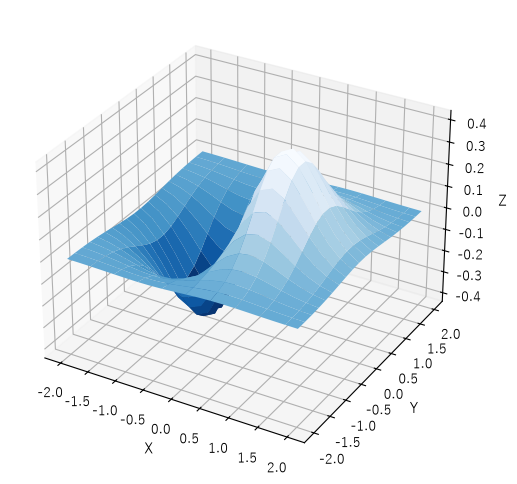

In [25]:
import mpl_toolkits.mplot3d  #❶

x, y = np.mgrid[-2:2:20j, -2:2:20j]  #❷
z = x * np.exp(-(x**2) - y**2)

fig = plt.figure(figsize=(8, 6))
ax = plt.subplot(111, projection="3d")  #❸
ax.plot_surface(x, y, z, rstride=2, cstride=1, cmap=plt.cm.Blues_r)  #❹
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z");

❶ `mplot3d` を読み込みます。3 次元の機能はこのモジュールにあります。❷ `mgrid` で x-y 平面の格子を作り、各点の高さ `z` を計算します。3 次元の曲面は、x、y、z が同じ形の 2 次元配列である必要があるので、`ogrid` では作れません。`imshow()` と違い、第 0 軸が x でも y でもかまいません。ここでは第 0 軸が x、第 1 軸が y です。

❸ `projection="3d"` でサブプロットを作ると、`Axes3D` が返ります。

:::{admonition} 投影モード
:class: note
投影モードは、データの座標を画面の座標に変える方法です。使える名前は次のコマンドで分かります。

```ipython
>>> from matplotlib import projections
>>> projections.get_projection_names()
['3d', 'aitoff', 'hammer', 'lambert', 'mollweide', 'polar', 'rectilinear']
```

`mplot3d` を読み込むと、この一覧に `'3d'` が加わります。`'aitoff'`、`'hammer'`、`'lambert'`、`'mollweide'` は地図の投影、`'polar'` は極座標、`'rectilinear'` は既定の直線の投影です。
:::

❹ `Axes3D` の `plot_surface()` で曲面を描きます。`x`、`y`、`z` はどれも形 `(20, 20)` の 2 次元配列です。`cmap` で高さと色の対応を決めます。`rstride` と `cstride` は、配列の第 0 軸と第 1 軸で何個おきに描くかです。配列が大きいときは間隔を大きくすると速くなります。

`Axes3D` には、ほかにも 3 次元の描画のメソッドがあります。公式のデモを見てください。

## まとめ

* 対数座標は `semilogx()`、`semilogy()`、`loglog()`。両対数の図をボード線図と呼ぶ。
* 極座標は `subplot(polar=True)` か `polar()` で作る。`rgrids()` と `thetagrids()` で格子を決める。
* 棒グラフは `bar()`。`plot()` の書式に点だけを書いても散布図になるが、点ごとに変えるなら `scatter()`。
* 画像は `imread()` と `imshow()`。PNG は 0〜1 の `float32`、JPEG は `uint8` で返る。
* 等高線は `contour()` と `contourf()`。`levels` で値を選べば、陰関数の曲線も描ける。
* 格子の色は `pcolormesh()`、三角形は `triplot()`、`tripcolor()`、`tricontour()` で描く。
* ベクトル場は `quiver()`。長さは `scale` と `scale_units`、向きは `angles` で決める。
* 3 次元は `mplot3d` の `Axes3D`。重いデータには PyVista を使う。